In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_squared_error, r2_score

# --- WHY? ---
# We need to import libraries so we can use pre-written tools for data manipulation (pandas),
# mathematical operations (numpy), plotting (matplotlib, seaborn), and evaluating our ML model (sklearn).

# --- HOW? ---
# Set display options so that we can view all columns and up to 100 rows in Colab outputs.
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
import pandas as pd

# --- WHAT & WHY? ---
# Load the dataset from an Excel file into a Pandas DataFrame so we can inspect and work with it.

# --- HOW? ---
# 'pd.read_excel()' reads the spreadsheet.
# 'df.head()' prints the first 5 rows to give us a preview.
# 'df.columns' lists the names of all variables (features) in our dataset.
df = pd.read_excel("/content/smart_class_energy_data (1).xlsx")
display(df.head())
print("\n")
print(df.columns)

,Num_Students,Outdoor_Temp,Time_of_Day,Humidity,Lights_On,Windows_Open,Fan_Speed,AC_Temp
0,33,34.714868,Morning,69.221654,1,0,2,26.911474
1,73,27.689434,Evening,75.267053,1,1,4,22.531882
2,73,38.544262,Afternoon,69.683302,0,0,3,23.523407
3,7,33.203330,Evening,89.243701,1,0,4,22.411541
4,35,33.565462,Evening,68.174341,0,0,1,26.139862




Index(['Num_Students', 'Outdoor_Temp', 'Time_of_Day', 'Humidity', 'Lights_On',
       'Windows_Open', 'Fan_Speed', 'AC_Temp'],
      dtype='object')


In [ ]:
# --- WHAT & WHY? ---
# Handle missing (null) values. Missing data can cause machine learning algorithms to fail.

# --- HOW? ---
# 'df.dropna()' removes any rows containing empty or NaN values.
# Note: To save these changes to our variable, we should ideally assign it back using df = df.dropna() or inplace=True.
df = df.dropna()
display(df)

,Num_Students,Outdoor_Temp,Time_of_Day,Humidity,Lights_On,Windows_Open,Fan_Speed,AC_Temp
0,33,34.714868,Morning,69.221654,1,0,2,26.911474
1,73,27.689434,Evening,75.267053,1,1,4,22.531882
2,73,38.544262,Afternoon,69.683302,0,0,3,23.523407
3,7,33.203330,Evening,89.243701,1,0,4,22.411541
4,35,33.565462,Evening,68.174341,0,0,1,26.139862
...,...,...,...,...,...,...,...,...
495,31,35.311169,Evening,71.632427,1,1,3,23.411115
496,62,33.835296,Evening,77.747009,1,0,4,21.676222
497,47,26.515593,Afternoon,78.597107,0,1,4,20.370864
498,33,35.886481,Afternoon,59.353728,1,1,5,20.237912


In [ ]:
from sklearn.preprocessing import LabelEncoder

# --- WHAT & WHY? ---
# Convert text data (categorical data) into numbers.
# Machine learning models can only compute mathematical equations, so features like 'Time_of_Day' (e.g., Morning, Afternoon, Evening) must be converted into numerical values (e.g., 0, 1, 2).

# --- HOW? ---
# 'LabelEncoder' automatically assigns a unique number to each unique text category.
le = LabelEncoder()
df["Time_of_Day"] = le.fit_transform(df["Time_of_Day"])

In [ ]:
# --- WHAT & WHY? ---
# Calculate the Correlation Matrix to understand how variables relate to one another.
# Correlation values range from -1 to +1.
# Positive correlation means as one variable increases, the other increases.
# Negative correlation means as one variable increases, the other decreases (e.g., higher Fan_Speed is strongly correlated with a lower AC_Temp, having a -0.64 value).

# --- HOW? ---
# 'df.corr()' calculates the Pearson correlation coefficient between all pairs of numeric columns.
corrmat = df.corr()
print(corrmat)

              Num_Students  Outdoor_Temp  Time_of_Day  Humidity  Lights_On  \
Num_Students      1.000000     -0.069036     0.059211  0.082841  -0.014156   
Outdoor_Temp     -0.069036      1.000000    -0.047031 -0.047611  -0.082780   
Time_of_Day       0.059211     -0.047031     1.000000  0.076527  -0.048490   
Humidity          0.082841     -0.047611     0.076527  1.000000   0.071968   
Lights_On        -0.014156     -0.082780    -0.048490  0.071968   1.000000   
Windows_Open      0.038090     -0.090445     0.027964 -0.010494  -0.022996   
Fan_Speed         0.387247      0.166994     0.070672  0.320569   0.004290   
AC_Temp          -0.409075     -0.181758    -0.032646 -0.329279  -0.022950   

              Windows_Open  Fan_Speed   AC_Temp  
Num_Students      0.038090   0.387247 -0.409075  
Outdoor_Temp     -0.090445   0.166994 -0.181758  
Time_of_Day       0.027964   0.070672 -0.032646  
Humidity         -0.010494   0.320569 -0.329279  
Lights_On        -0.022996   0.004290 -0.022950

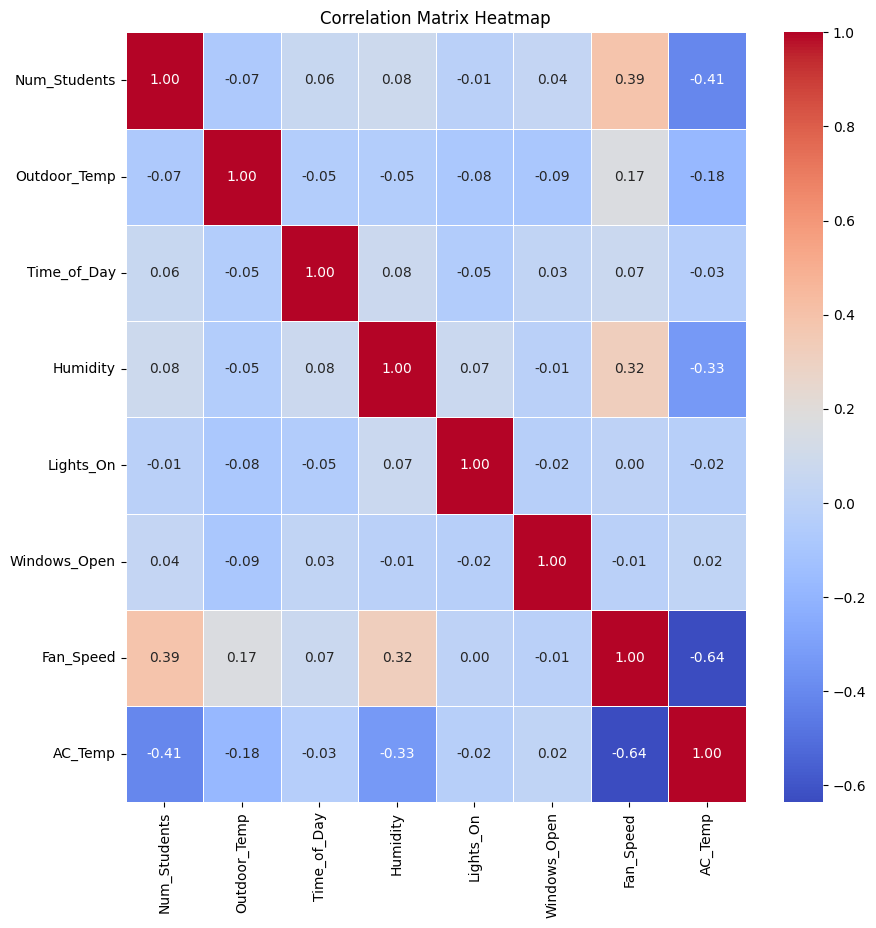

In [ ]:
# --- WHAT & WHY? ---
# Visualize the correlation matrix using a Heatmap. This makes it much easier to identify patterns
# than reading raw numbers in a table.

# --- HOW? ---
# 'sns.heatmap' plots the grid.
# 'annot=True' writes the actual correlation values inside each box.
# 'cmap="coolwarm"' sets colors where red represents strong positive correlation and blue represents strong negative correlation.
plt.figure(figsize=(10,10))
sns.heatmap(corrmat, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix Heatmap")
plt.show()

In [ ]:
# --- WHAT & WHY? ---
# Remove outliers (extreme/unusual data points) using the IQR (Interquartile Range) method.
# Outliers can skew our machine learning model's predictions, leading to poorer performance.

# --- HOW? ---
# 1. 'q1' is the 25th percentile, 'q3' is the 75th percentile.
# 2. 'IQR' is the middle 50% range (q3 - q1).
# 3. We set lower (lb) and upper (ub) bounds: anything beyond [q1 - 1.5*IQR] or [q3 + 1.5*IQR] is an outlier and gets filtered out.
def rem_outliere_iqr(df):
  # Select only numeric columns to calculate quantiles
  numeric_df = df.select_dtypes(include=[np.number])
  q1 = numeric_df.quantile(0.25)
  q3 = numeric_df.quantile(0.75)
  IQR = q3 - q1
  lb = q1 - 1.5 * IQR
  ub = q3 + 1.5 * IQR

  # Keep rows where values are within the lower and upper bounds
  return df[~((numeric_df < lb) | (numeric_df > ub)).any(axis=1)]

df_clean = rem_outliere_iqr(df)

In [ ]:
# --- WHAT & WHY? ---
# Re-calculate correlation after removing outliers to see if relationships between variables changed or became cleaner.
cormat = df_clean.corr()

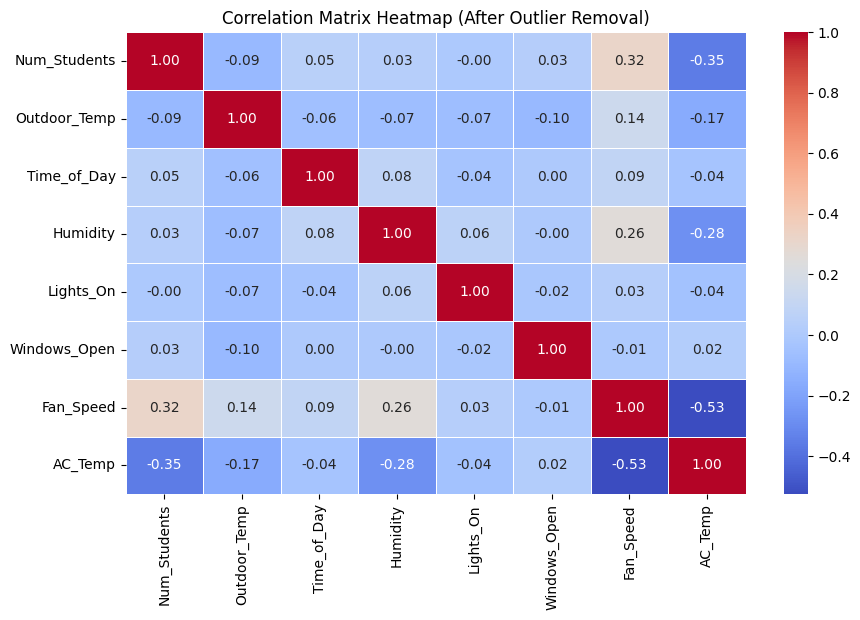

In [ ]:
# --- WHAT & WHY? ---
# Plot the correlation heatmap again for the clean dataset to inspect differences.
plt.figure(figsize=(10,6))
sns.heatmap(cormat, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix Heatmap (After Outlier Removal)")
plt.show()

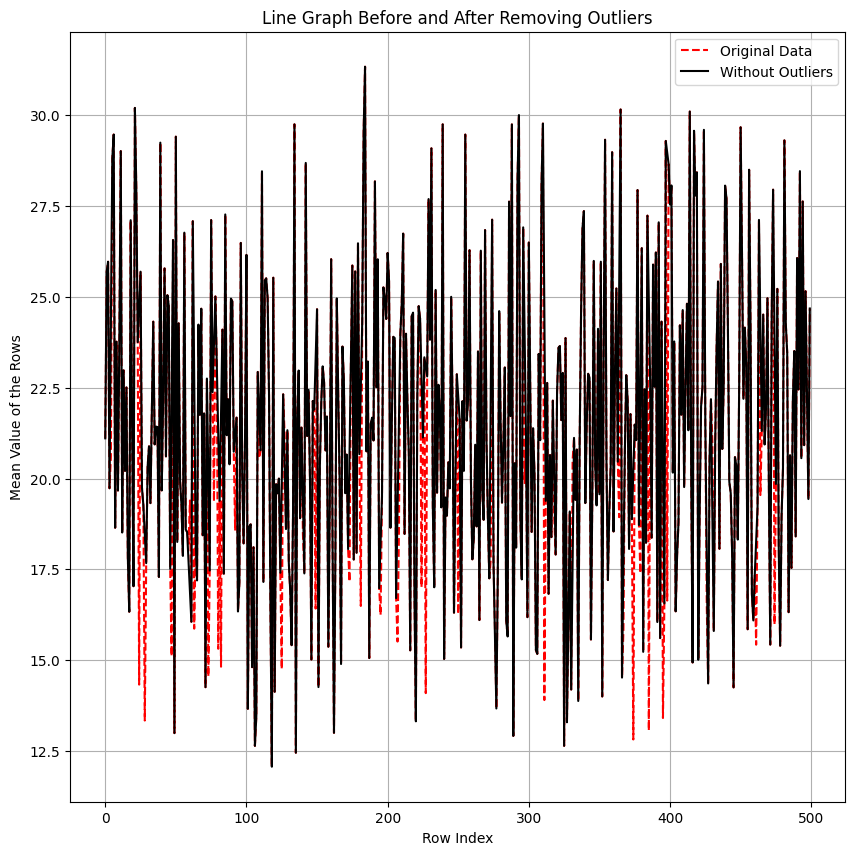

In [ ]:
# --- WHAT & WHY? ---
# Visualizing the row-wise mean values before and after outlier removal to see which extreme rows were removed.

# --- HOW? ---
# We plot the average values of each row (axis=1) for both the original dataset (red dashed line) and cleaned dataset (black solid line).
# Where the red dashed lines drop down alone, those represent the outlier rows that were successfully filtered out.
plt.figure(figsize=(10,10))
plt.plot(df.index, df.mean(axis=1, numeric_only=True), label="Original Data", linestyle='dashed', color="red")
plt.plot(df_clean.index, df_clean.mean(axis=1, numeric_only=True), label="Without Outliers", color='black')
plt.title("Line Graph Before and After Removing Outliers")
plt.xlabel("Row Index")
plt.ylabel("Mean Value of the Rows")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# --- WHAT & WHY? ---
# Split the dataset into features (Independent variables, X) and target (Dependent variable, Y).
# We want to use classroom conditions (X) to predict the target setting 'AC_Temp' (Y).

# --- HOW? ---
# 'x' contains all columns except the target column ('AC_Temp').
# 'y' contains only the target column ('AC_Temp').
x = df.drop(columns=["AC_Temp"])
y = df["AC_Temp"]

display(x.head())
display(y.head())

,Num_Students,Outdoor_Temp,Time_of_Day,Humidity,Lights_On,Windows_Open,Fan_Speed
0,33,34.714868,2,69.221654,1,0,2
1,73,27.689434,1,75.267053,1,1,4
2,73,38.544262,0,69.683302,0,0,3
3,7,33.203330,1,89.243701,1,0,4
4,35,33.565462,1,68.174341,0,0,1


,AC_Temp
0,26.911474
1,22.531882
2,23.523407
3,22.411541
4,26.139862


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# --- WHAT & WHY? ---
# We split the data into Training and Testing sets, then train a Linear Regression model.
# Training Set: Used to teach the model how features relate to the target.
# Testing Set: Used to test how well the model predicts on unseen data (essential to avoid overfitting).

# --- HOW? ---
# 'train_test_split' reserves 20 samples for testing, and the rest for training.
# 'model.fit()' calculates the best-fit line (finds optimal coefficients/weights) for our linear equation.
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=20, random_state=40)
model = LinearRegression()
model.fit(x_train, y_train)

LinearRegression()

In [ ]:
# --- WHAT & WHY? ---
# Make predictions on the test set and calculate Mean Squared Error (MSE) to evaluate performance.
# MSE measures the average squared difference between actual target values and predicted values. Lower is better!

# --- HOW? ---
# 'model.predict(x_test)' generates predictions.
# 'mean_squared_error(y_test, y_pred)' calculates the error metric.
y_pred = model.predict(x_test)
mse = mean_squared_error(y_test, y_pred)
print(f"Mean Squared Error (MSE): {mse}")

Mean Squared Error (MSE): 1.9205853624119569


In [ ]:
# --- WHAT & WHY? ---
# Calculate R-squared (R²) score, also known as the Coefficient of Determination.
# It tells us how much of the variance in the target (AC_Temp) can be explained by our features.
# An R² score of 0.51 means about 51% of the variation in AC temperature is explained by our model.

# --- HOW? ---
# 'r2_score()' compares actual test targets with predicted values.
r2 = r2_score(y_test, y_pred)
print(f"R2 Score: {r2}")

R2 Score: 0.5078275137110061


In [ ]:
# --- WHAT & WHY? ---
# Predict the AC Temperature for a brand-new, hypothetical classroom scenario.
# This demonstrates how the model can be used in a production or real-world environment.

# --- HOW? ---
# Define feature values as a 2D numpy array matching the order of columns in 'x'.
# Note: We pass a Pandas DataFrame containing feature names to avoid any library feature name warnings.
new_sample = pd.DataFrame([[55, 32.145236, 2, 85.456921, 0, 1, 3]], columns=x.columns)
prediction = model.predict(new_sample)
print(f"Predicted AC Temp Output: {prediction[0]:.4f}")

Predicted AC Temp Output: 22.8469


Confusion Matrix:
[[ 5  1]
 [ 1 13]]


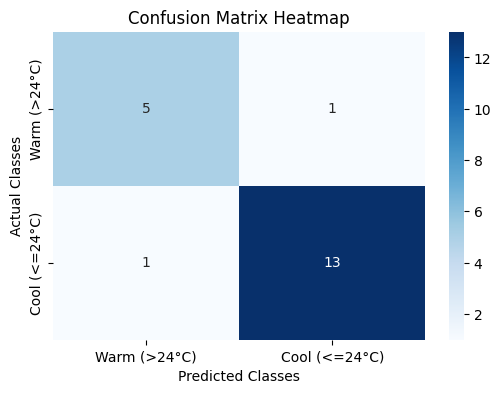

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
import seaborn as sns
import matplotlib.pyplot as plt

# --- WHAT & WHY? ---
# Logistic Regression is used for CLASSIFICATION (predicting categories, e.g., Yes/No or Cool/Warm).
# Since 'AC_Temp' is a continuous number, we convert it into a binary classification target:
# '1' (Cool AC setting, <= 24 degrees) and '0' (Warm AC setting, > 24 degrees).
# We then train the model and evaluate it using a Confusion Matrix to see correct vs. incorrect classifications.

# --- HOW? ---
# 1. We prepare features 'x' and classification target 'y_class' directly in this cell to prevent NameErrors.
# 2. Split into train/test sets.
# 3. Fit the LogisticRegression classifier.
# 4. Generate and plot the Confusion Matrix heatmap.

# Prepare features from our cleaned dataset 'df_clean' (or 'df' if df_clean is not yet defined)
data_source = df_clean if 'df_clean' in locals() else df
x_logistic = data_source.drop(columns=["AC_Temp"])
y_temp = data_source["AC_Temp"]

# Convert continuous AC_Temp to Binary Categories (Cool vs Warm)
y_class = (y_temp <= 24.0).astype(int)

# Split into training and testing sets
x_train_c, x_test_c, y_train_c, y_test_c = train_test_split(x_logistic, y_class, test_size=20, random_state=40)

# Train the Logistic Regression Model
log_model = LogisticRegression(max_iter=1000)
log_model.fit(x_train_c, y_train_c)

# Predict categories on test data
y_pred_c = log_model.predict(x_test_c)

# Calculate Confusion Matrix
cm = confusion_matrix(y_test_c, y_pred_c)
print("Confusion Matrix:")
print(cm)

# Plot the Confusion Matrix as a Heatmap for clear visualization
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Warm (>24°C)", "Cool (<=24°C)"], yticklabels=["Warm (>24°C)", "Cool (<=24°C)"])
plt.title("Confusion Matrix Heatmap")
plt.xlabel("Predicted Classes")
plt.ylabel("Actual Classes")
plt.show()

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

# --- WHAT & WHY? ---
# Multiple Linear Regression predicts a continuous target using MULTIPLE input features together.
# It calculates a coefficient (slope weight) for each feature to show how much that specific feature impacts the target.

# --- HOW? ---
# We define features 'x' and target 'y' directly in this cell to prevent NameErrors.
# We use 'LinearRegression()' on our entire input dataset 'x_train' (which contains all features like Humidity, Fan_Speed, etc.).
# 'multi_model.coef_' prints the weight given to each feature.
# 'multi_model.intercept_' is the baseline constant value when all features are zero.

# Prepare features from our cleaned dataset 'df_clean' (or 'df' if df_clean is not yet defined)
data_source = df_clean if 'df_clean' in locals() else df
x_multi = data_source.drop(columns=["AC_Temp"])
y_multi = data_source["AC_Temp"]

# Split into training and testing sets
x_train_m, x_test_m, y_train_m, y_test_m = train_test_split(x_multi, y_multi, test_size=20, random_state=40)

# Train the Multiple Linear Regression Model
multi_model = LinearRegression()
multi_model.fit(x_train_m, y_train_m)

print("=== Multiple Regression Coefficients ===\n")
for feature, coef in zip(x_multi.columns, multi_model.coef_):
    print(f"{feature}: {coef:.4f}")

print(f"\nBaseline Constant (Intercept): {multi_model.intercept_:.4f}")

=== Multiple Regression Coefficients ===

Num_Students: -0.0165
Outdoor_Temp: -0.0521
Time_of_Day: 0.0424
Humidity: -0.0199
Lights_On: -0.1460
Windows_Open: 0.1112
Fan_Speed: -0.7464

Baseline Constant (Intercept): 29.1005
